# Hydraulic analysis of Koto city

In this notebook you will the different parts of the hydraulic analysis of Koto city, district within Tokyo metropolis.
Data used to calculate and determine hydraulic parameters were gatehered from the following sources:
- Precipitation and other atmospheric data: JRA-3Q (Japanese Reanalysis for Three Quarters of a Century) courtesy of the United States National Science Foundation  
- Water level data: Water Information System courtesy of the Ministry of Land, Infrastructure, Transport and Tourism of Japan

In [85]:
#Packages used in this analysis
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats


In [86]:
#import of atmospheric data 
import xarray
filename = 'https://data.gdex.ucar.edu/d640000/kerchunk/anl_isentrop-remote-https.parq'
ds = xarray.open_dataset(filename, engine='kerchunk')
ds['bvf2-theta-an-gauss'] # Square of Brunt-Vaisala frequency

<xarray.DataArray 'bvf2-theta-an-gauss' (time: 114572, isentropic_level: 36,
                                         lat: 480, lon: 960)> Size: 8TB
[1900611993600 values with dtype=float32]
Coordinates:
  * time              (time) datetime64[ns] 917kB 1947-09-01 ... 2026-01-31T1...
  * isentropic_level  (isentropic_level) float64 288B 270.0 280.0 ... 4e+03
  * lat               (lat) float64 4kB 89.71 89.34 88.97 ... -89.34 -89.71
  * lon               (lon) float64 8kB 0.0 0.375 0.75 ... 358.9 359.2 359.6
Attributes: (12/73)
    group:                                               anl_isentrop
    jma_group_description:                               Isentropic analysis ...
    rda_group_description:                               JRA-3Q isentropic an...
    rda_group_number:                                    1
    short_name:                                          bvf2-theta-an-gauss
    jma_short_name:                                      bvf2
    ...                                                  ...
    angular_speed_of_earth_rotation:                     7.29245e-5 rad s-1
    gravitational_accleration:                           9.80665 m s-2
    gas_constant_for_dry_air:                            287.04 J K-1 kg-1
    specific_heat_of_dry_air_at_constant_pressure:       1004.6 J K-1 kg-1
    latent_heat_of_vaporization:                         2.507e+6 J kg-1
    solar_constant:                                      1365 W m-2

In [87]:
def parse_jp_datetime(year, dt):
    if pd.isna(dt):
        return pd.NaT
    dt = str(dt).replace("年", "").replace("月", "/").replace("日", "").strip()
    if dt.endswith(" 24:00"):
        dt = dt.replace(" 24:00", " 00:00")
        d = pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")
        if pd.notna(d):
            return d + pd.Timedelta(days=1)
        return d
    return pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")

In [88]:
sentinel_values = ["", "-", "$", "nan", "NaN", "None", "0.00", "-9999.00"]

df = sumida_down.copy()
df["date_minWL"] = df["date_minWL"].replace(sentinel_values, pd.NA)

df["date_minWL"] = df["date_minWL"].map(clean_date)

# If 24:00 is meant to be next day, add one day after parsing
tmp = pd.to_datetime(df["year"].astype(str) + "/" + df["date_minWL"],
                    format="%Y/%m/%d %H:%M", errors="coerce")

# fix deliberate 24:00 cases
mask = df["date_minWL"].str.contains(" 00:00", na=False) & df["date_minWL"].str.contains("24:00", na=False)
# safer: normalize before parse, then add one day where needed

In [89]:
# Read and process hydraulic data for Sumida River (upstream)
from io import StringIO

with open("iwabuchi_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
    lines = f.readlines()

valid_lines = []
for line in lines:
    s = line.strip()
    if not s or s.startswith("#"):
        continue
    if s[:4].isdigit() and "," in s:
        valid_lines.append(s)

data_sumida_up = "\n".join(valid_lines)

sumida_up = pd.read_csv(
    StringIO(data_sumida_up),
    sep=",",
    header=None,
    engine="python",
    on_bad_lines="skip",
    na_values=["-9999.00", "$", "-", "", "0.00"])

# Select relevant columns and rename
sumida_up = sumida_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
sumida_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
                      'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# Clean and convert date columns to datetime format
sumida_up["date_maxWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(sumida_up["year"], sumida_up["date_maxWL"])]

sumida_up["date_minWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(sumida_up["year"], sumida_up["date_minWL"])]


In [90]:
sumida_up.head()

,year,maxWL,date_maxWL,wetmeanWL+STD,wetmeanWL,wetmeanWL-STD,drymeanWL,minWL,date_minWL,meanWL
0,1930,3.12,1930-08-02 01:00:00,1.41,1.30,1.18,1.03,0.29,1930-05-02 16:00:00,1.31
1,1931,3.02,1931-10-14 08:00:00,1.38,1.28,1.20,1.06,0.17,1931-02-14 00:00:00,1.31
2,1932,2.99,1932-11-16 10:00:00,1.41,1.31,1.20,1.05,0.17,1932-01-21 00:00:00,1.33
3,1933,2.75,1933-09-05 07:00:00,1.38,1.27,1.19,1.05,0.15,1933-12-07 04:00:00,1.30
4,1934,2.63,1934-10-09 08:00:00,1.35,1.26,1.18,1.05,0.12,1934-01-15 01:00:00,1.28


In [91]:
# Read and process hydraulic data for Sumida River (downstream)
from io import StringIO

with open("reiganjima_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
    lines = f.readlines()

valid_lines = []
for line in lines:
    s = line.strip()
    if not s or s.startswith("#"):
        continue
    if s[:4].isdigit() and "," in s:
        valid_lines.append(s)

data_sumida_down = "\n".join(valid_lines)

sumida_down = pd.read_csv(
    StringIO(data_sumida_down),
    sep=",",
    header=None,
    engine="python",
    on_bad_lines="skip",
    na_values=["-9999.00", "$", "-", "", "0.00"])

# Select relevant columns and rename
sumida_down = sumida_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
sumida_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# Clean and convert date columns to datetime format
sumida_down["date_maxWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(sumida_down["year"], sumida_down["date_maxWL"])]

sumida_down["date_minWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(sumida_down["year"], sumida_down["date_minWL"])]




In [92]:
h = np.array(sumida_down['date_maxWL'])
print(h)

['1930-09-23T18:00:00.000000000' '1931-10-14T07:00:00.000000000'
 '1932-09-01T05:00:00.000000000' '1933-09-05T06:00:00.000000000'
 '1934-09-21T17:00:00.000000000' '1935-08-29T18:00:00.000000000'
 '1936-09-16T06:00:00.000000000' '1937-09-11T21:00:00.000000000'
 '1938-12-24T08:00:00.000000000' '1939-08-16T18:00:00.000000000'
 '1940-08-06T19:00:00.000000000' '1941-03-12T05:00:00.000000000'
 '1942-06-15T05:00:00.000000000' '1943-10-03T19:00:00.000000000'
 '1944-08-07T20:00:00.000000000' '1945-04-11T05:00:00.000000000'
 '1946-12-09T06:00:00.000000000' '1947-09-15T05:00:00.000000000'
 '1948-09-16T17:00:00.000000000' '1949-08-31T22:00:00.000000000'
 '1950-10-13T07:00:00.000000000' '1951-10-15T18:00:00.000000000'
 '1952-08-08T06:00:00.000000000' '1953-09-25T19:00:00.000000000'
 '1954-09-26T16:00:00.000000000' '1955-12-29T06:00:00.000000000'
 '1956-01-28T17:00:00.000000000' '1957-12-13T10:00:00.000000000'
 '1958-09-18T08:00:00.000000000' '1959-09-18T06:00:00.000000000'
 '1960-10-21T17:00:00.000

In [93]:
# Read and process hydraulic data for Arakawa River (upstream)
from io import StringIO

with open("nanbata_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
    lines = f.readlines()

valid_lines = []
for line in lines:
    s = line.strip()
    if not s or s.startswith("#"):
        continue
    if s[:4].isdigit() and "," in s:
        valid_lines.append(s)

data_arakawa_up = "\n".join(valid_lines)

arakawa_up = pd.read_csv(
    StringIO(data_arakawa_up),
    sep=",",
    header=None,
    engine="python",
    on_bad_lines="skip",
    na_values=["-9999.00", "$", "-", "", "0.00"])

# Select relevant columns and rename
arakawa_up = arakawa_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
arakawa_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
                      'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# Clean and convert date columns to datetime format
arakawa_up["date_maxWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_up["year"], arakawa_up["date_maxWL"])]

arakawa_up["date_minWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_up["year"], arakawa_up["date_minWL"])]

In [94]:
# Read and process hydraulic data for Arakawa River (midstream)
from io import StringIO

with open("nishiarai_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
    lines = f.readlines()

valid_lines = []
for line in lines:
    s = line.strip()
    if not s or s.startswith("#"):
        continue
    if s[:4].isdigit() and "," in s:
        valid_lines.append(s)

data_arakawa_mid = "\n".join(valid_lines)

arakawa_mid = pd.read_csv(
    StringIO(data_arakawa_mid),
    sep=",",
    header=None,
    engine="python",
    on_bad_lines="skip",
    na_values=["-9999.00", "$", "-", "", "0.00"])


# Select relevant columns and rename
arakawa_mid = arakawa_mid[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
arakawa_mid.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# Clean and convert date columns to datetime format
arakawa_mid["date_maxWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_mid["year"], arakawa_mid["date_maxWL"])]

arakawa_mid["date_minWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_mid["year"], arakawa_mid["date_minWL"])]


In [95]:
# Read and process hydraulic data for Arakawa River (downstream)
from io import StringIO

with open("onagigawa_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
    lines = f.readlines()

valid_lines = []
for line in lines:
    s = line.strip()
    if not s or s.startswith("#"):
        continue
    if s[:4].isdigit() and "," in s:
        valid_lines.append(s)

data_arakawa_down = "\n".join(valid_lines)

arakawa_down = pd.read_csv(
    StringIO(data_arakawa_down),
    sep=",",
    header=None,
    engine="python",
    on_bad_lines="skip",
    na_values=["-9999.00", "$", "-", "", "0.00"])

# Select relevant columns and rename
arakawa_down = arakawa_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
arakawa_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# Clean and convert date columns to datetime format
arakawa_down["date_maxWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_down["year"], arakawa_down["date_maxWL"])]

arakawa_down["date_minWL"] = [parse_jp_datetime(y, d)
    for y, d in zip(arakawa_down["year"], arakawa_down["date_minWL"])]


In [96]:
sumida_up.head()

,year,maxWL,date_maxWL,wetmeanWL+STD,wetmeanWL,wetmeanWL-STD,drymeanWL,minWL,date_minWL,meanWL
0,1930,3.12,1930-08-02 01:00:00,1.41,1.30,1.18,1.03,0.29,1930-05-02 16:00:00,1.31
1,1931,3.02,1931-10-14 08:00:00,1.38,1.28,1.20,1.06,0.17,1931-02-14 00:00:00,1.31
2,1932,2.99,1932-11-16 10:00:00,1.41,1.31,1.20,1.05,0.17,1932-01-21 00:00:00,1.33
3,1933,2.75,1933-09-05 07:00:00,1.38,1.27,1.19,1.05,0.15,1933-12-07 04:00:00,1.30
4,1934,2.63,1934-10-09 08:00:00,1.35,1.26,1.18,1.05,0.12,1934-01-15 01:00:00,1.28


In [97]:
sumida_down.head()

,year,maxWL,date_maxWL,wetmeanWL+STD,wetmeanWL,wetmeanWL-STD,drymeanWL,minWL,date_minWL,meanWL
0,1930,2.23,1930-09-23 18:00:00,1.22,1.14,1.04,0.90,-0.24,1930-02-14 00:00:00,1.13
1,1931,2.33,1931-10-14 07:00:00,1.18,1.12,1.06,0.95,-0.15,1931-01-06 01:00:00,1.13
2,1932,2.29,1932-09-01 05:00:00,1.19,1.11,1.02,0.88,-0.18,1932-12-30 01:00:00,1.11
3,1933,2.48,1933-09-05 06:00:00,1.18,1.10,1.02,0.91,-0.12,1933-01-24 23:00:00,1.11
4,1934,2.52,1934-09-21 17:00:00,1.23,1.15,1.06,0.95,-0.18,1934-01-16 00:00:00,1.15


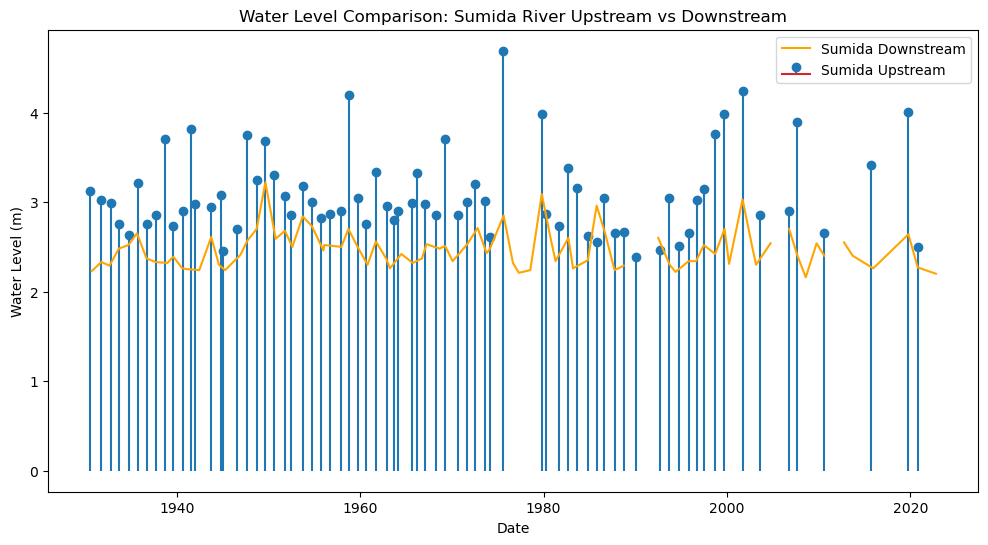

In [100]:
plt.figure(figsize=(12, 6))
plt.stem(sumida_up['date_maxWL'], sumida_up['maxWL'], label='Sumida Upstream')
plt.plot(sumida_down['date_maxWL'], sumida_down['maxWL'], label='Sumida Downstream', color='orange')
plt.xlabel('Date')
plt.ylabel('Water Level (m)')
plt.title('Water Level Comparison: Sumida River Upstream vs Downstream')
plt.legend()